# 08 — Modelo Final LightGBM (nível de AMOSTRA)

## Fluxo
```
Para cada pré-processamento com sua config (NB06) e hiperparâmetros (NB07):

  Matriz ROI [19 × 226]
    ↓  StratifiedKFold k=3 (nível de amostra)
       → pré-proc ajustado no TREINO (sem leakage)
       → seleção de bandas no TREINO
       → Gold no nível de amostra
       → LightGBM com hiperparâmetros otimizados (NB07)
    → métricas sobre as 19 predições held-out
    → teste de permutação (p-valor honesto)
```
> **Unidade = amostra** (não pixel): elimina a pseudo-replicação. **StratifiedKFold
> k=3** (não Leave-One-Out): a estratificação mantém a prevalência do treino
> constante, evitando o vazamento de rótulo do LOO com N pequeno. O desempenho
> aqui é muito menor que o pixel-level do parcial — o teste de permutação mostra
> se é distinguível do acaso. Ver também o confound resistente×ATCC×ordem (Limitações).

In [1]:
%matplotlib inline
import sys, json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import warnings
warnings.filterwarnings("ignore")

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay,
)
from lightgbm import LGBMClassifier

ROOT_DIR = Path("..").resolve()
sys.path.append(str(ROOT_DIR))
sys.path.append(str(ROOT_DIR / "src"))

from src.feature_engineering import build_gold_matrix
from src.feature_selectors   import selecionar_bandas_consenso
from src.preprocessing        import build_preprocessor
from src.modeling_roi         import load_roi_matrix, run_logo, teste_permutacao

print("Imports OK")

Imports OK


## Carregar configs otimizadas (notebook 07)

In [2]:
CONFIG_DIR = ROOT_DIR / "data" / "gold level" / "features_extraidas"

CONFIGS = {}
for pre in ["MSC", "RAW", "SavGol", "ZScore"]:
    caminho = CONFIG_DIR / f"config_pre_{pre}.json"
    with open(caminho, encoding="utf-8") as f:
        CONFIGS[pre] = json.load(f)

print("Configs carregadas (hiperparâmetros otimizados no NB07, nível de amostra):")
for pre, cfg in CONFIGS.items():
    print(f"  {pre:8s}: pre={cfg.get('metodo_pre', pre.lower())}, "
          f"selecao={cfg['metodo_selecao']}, derivadas={cfg['incluir_features_derivadas']}, "
          f"k={cfg['k_bandas']} | F1_cv={cfg['metricas_cv']:.3f}")
    for param, val in cfg["melhores_params"].items():
        print(f"             {param}: {val}")

Configs carregadas (hiperparâmetros otimizados no NB07, nível de amostra):
  MSC     : pre=msc, selecao=mi, derivadas=False, k=15 | F1_cv=1.000
             boosting_type: gbdt
             feature_fraction: 0.7
             lambda_l1: 0.0
             lambda_l2: 0.1
             learning_rate: 0.01
             max_depth: 3
             min_child_samples: 2
             num_leaves: 7
  RAW     : pre=raw, selecao=None, derivadas=True, k=15 | F1_cv=0.333
             boosting_type: gbdt
             feature_fraction: 0.7
             lambda_l1: 0.0
             lambda_l2: 0.1
             learning_rate: 0.01
             max_depth: 3
             min_child_samples: 2
             num_leaves: 7
  SavGol  : pre=savigol, selecao=None, derivadas=True, k=15 | F1_cv=0.143
             boosting_type: gbdt
             feature_fraction: 0.7
             lambda_l1: 0.0
             lambda_l2: 0.1
             learning_rate: 0.01
             max_depth: 3
             min_child_samples: 10
      

## Carregar datasets Silver

In [3]:
# Matriz ROI (espectro médio por amostra) — conforme o plano [n_amostras × n_bandas].
# O pré-processamento é aplicado DENTRO de cada fold (anti-leakage).
df_roi = load_roi_matrix()
band_cols = [c for c in df_roi.columns if c not in ("sample_id", "target")]

_MAP_PRE = {"RAW": "raw", "MSC": "msc", "SavGol": "savigol", "ZScore": "z_score"}
_MAP_SEL = lambda s: None if s in (None, "None") else s

def banda_para_nm(b):
    """Índice de banda ('b188') → comprimento de onda (SisuCHEMA 1000–2500 nm)."""
    i = int(str(b).lstrip("b"))
    return 1000 + i * (1500 / (len(band_cols) - 1))

def params_completos(cfg):
    """Junta os params fixos do LightGBM com os otimizados no NB07."""
    base = dict(n_estimators=100, class_weight="balanced", importance_type="gain",
                random_state=42, verbose=-1)
    return {**base, **cfg["melhores_params"]}

print(f"Matriz ROI: {df_roi.shape[0]} amostras × {len(band_cols)} bandas "
      f"({int(df_roi['target'].sum())} resistentes)")

Matriz ROI: 19 amostras × 226 bandas (3 resistentes)


## Efeito dos Pré-processamentos nos Espectros

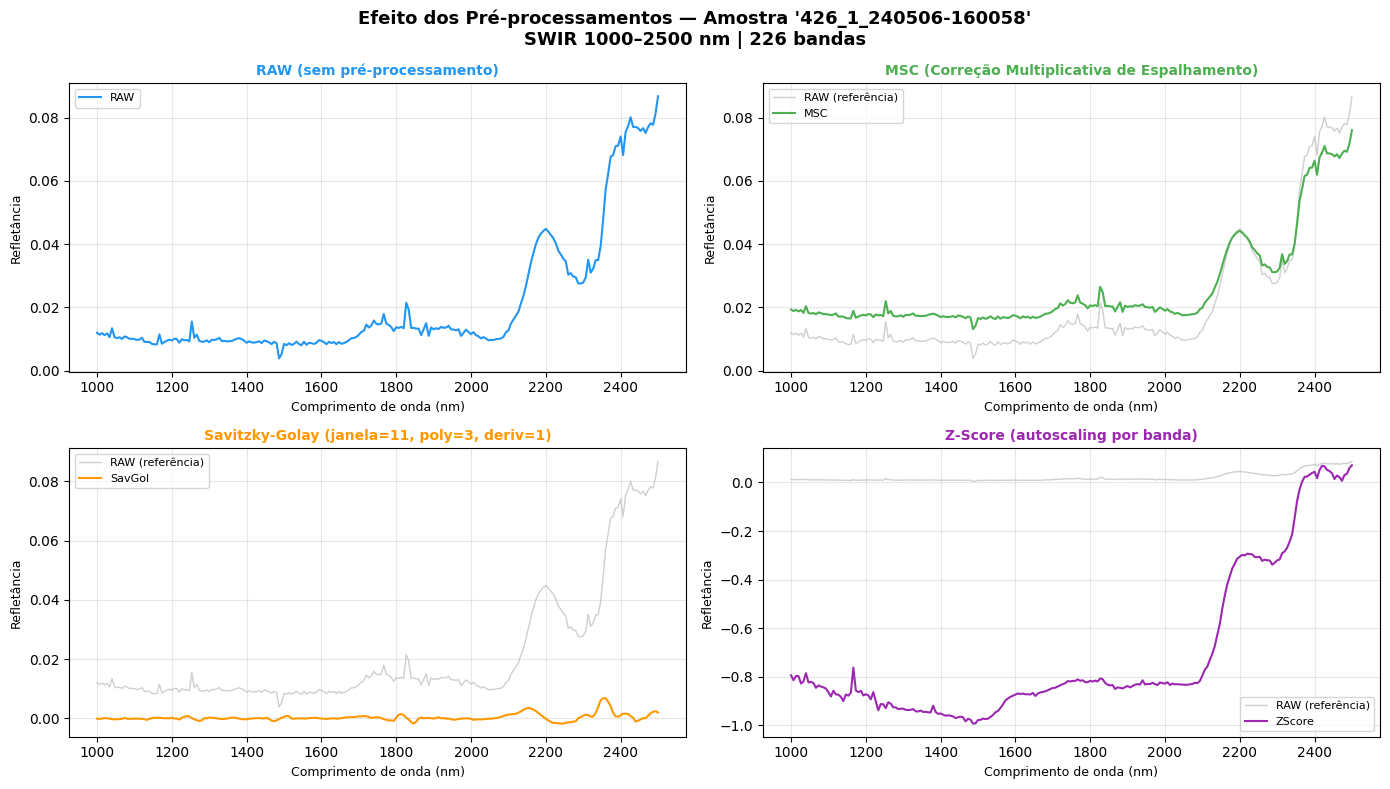

Figura salva: comparacao_preprocessamentos_espectro.png


In [4]:
OUTPUT_DIR = ROOT_DIR / "data" / "gold level" / "features_extraidas"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Efeito dos 4 pré-processamentos no espectro médio de UMA amostra.
# Pré-proc aplicado globalmente aqui APENAS para visualização.
SAMPLE_ID_ALVO = "426_1_240506-160058"  # amostra com melhor detecção de ROI (círculo mais preciso)
if SAMPLE_ID_ALVO in df_roi["sample_id"].values:
    AMOSTRA_IDX = int(df_roi.index[df_roi["sample_id"] == SAMPLE_ID_ALVO][0])
else:
    AMOSTRA_IDX = 0
sample_id   = df_roi.iloc[AMOSTRA_IDX]["sample_id"]
wl          = [banda_para_nm(b) for b in band_cols]
raw_espec   = df_roi.iloc[AMOSTRA_IDX][band_cols].values.astype(float)

cores_pre  = {"MSC": "#4CAF50", "RAW": "#2196F3", "SavGol": "#FF9800", "ZScore": "#9C27B0"}
titulos    = {
    "RAW":    "RAW (sem pré-processamento)",
    "MSC":    "MSC (Correção Multiplicativa de Espalhamento)",
    "SavGol": "Savitzky-Golay (janela=11, poly=3, deriv=1)",
    "ZScore": "Z-Score (autoscaling por banda)",
}

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle(
    f"Efeito dos Pré-processamentos — Amostra '{sample_id}'\n"
    f"SWIR 1000–2500 nm | {len(band_cols)} bandas",
    fontsize=13, fontweight="bold")

for ax, nome_pre in zip(axes.flat, ["RAW", "MSC", "SavGol", "ZScore"]):
    pre = build_preprocessor(_MAP_PRE[nome_pre])
    espectro = pre.fit_transform(df_roi[band_cols].values)[AMOSTRA_IDX]

    if nome_pre != "RAW":
        ax.plot(wl, raw_espec, color="#BBBBBB", linewidth=1, alpha=0.7,
                label="RAW (referência)")
    ax.plot(wl, espectro, color=cores_pre[nome_pre], linewidth=1.5, label=nome_pre)
    ax.set_title(titulos[nome_pre], fontsize=10, fontweight="bold", color=cores_pre[nome_pre])
    ax.set_xlabel("Comprimento de onda (nm)", fontsize=9)
    ax.set_ylabel("Refletância", fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "comparacao_preprocessamentos_espectro.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figura salva: comparacao_preprocessamentos_espectro.png")

## Utilitários internos

In [5]:
# Avaliação no nível de AMOSTRA via LOGO-CV, com os hiperparâmetros do NB07.
# Pré-proc e seleção de bandas ajustados dentro de cada fold (sem leakage).

def avaliar_logo(nome_pre):
    cfg = CONFIGS[nome_pre]
    return run_logo(
        df_roi,
        metodo_pre        = cfg.get("metodo_pre", _MAP_PRE[nome_pre]),
        metodo_sel        = _MAP_SEL(cfg["metodo_selecao"]),
        k                 = cfg["k_bandas"],
        model_params      = params_completos(cfg),
        incluir_derivadas = cfg["incluir_features_derivadas"],
    )

print("Utilitários carregados ✓")

Utilitários carregados ✓


## Avaliação final — StratifiedKFold k=3 (nível de amostra)

Cada pré-processamento usa seus hiperparâmetros otimizados (NB07). Métricas
calculadas sobre as 19 predições held-out, mais teste de permutação no melhor
pré-processamento para o p-valor honesto.

In [6]:
import time

OUTPUT_DIR = ROOT_DIR / "data" / "gold level" / "features_extraidas"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATH = OUTPUT_DIR / "resultados_notebook08_roi.csv"

resultados = []
predicoes_por_pre = {}

for nome_pre in ["MSC", "RAW", "SavGol", "ZScore"]:
    print(f"\n{'='*55}\n[{nome_pre}]")
    t0 = time.time()
    res = avaliar_logo(nome_pre)
    m = res["metricas"]
    predicoes_por_pre[nome_pre] = res["predicoes"]
    resultados.append({
        "Pré-proc": nome_pre,
        "F1-score": m["F1"], "ROC-AUC": m["ROC_AUC"], "Recall": m["Recall"],
        "Precisão": m["Precisao"], "Acurácia": m["Acuracia"],
        "n_amostras": m["n_amostras"], "n_resistentes": m["n_resistentes"],
    })
    print(f"  LOGO | F1={m['F1']:.3f} | AUC={m['ROC_AUC']:.3f} | "
          f"Recall={m['Recall']:.3f} | {time.time()-t0:.0f}s")

df_res = pd.DataFrame(resultados)
df_res.to_csv(CSV_PATH, index=False)
print(f"\n[OK] {CSV_PATH.name}")

# ── Teste de permutação no melhor pré-processamento (p-valor honesto) ─────────
melhor_pre = df_res.loc[df_res["F1-score"].idxmax(), "Pré-proc"]
print(f"\n{'='*55}\nTESTE DE PERMUTAÇÃO — {melhor_pre} (n_perm=200)")
cfg_b = CONFIGS[melhor_pre]
perm = teste_permutacao(
    df_roi,
    metodo_pre        = cfg_b.get("metodo_pre", _MAP_PRE[melhor_pre]),
    metodo_sel        = _MAP_SEL(cfg_b["metodo_selecao"]),
    k                 = cfg_b["k_bandas"],
    model_params      = params_completos(cfg_b),
    incluir_derivadas = cfg_b["incluir_features_derivadas"],
    metrica="ROC_AUC", n_perm=200,
)


[MSC]


  LOGO | F1=0.250 | AUC=0.688 | Recall=0.333 | 7s

[RAW]


  LOGO | F1=0.286 | AUC=0.562 | Recall=0.333 | 0s

[SavGol]


  LOGO | F1=0.267 | AUC=0.521 | Recall=0.667 | 0s

[ZScore]


  LOGO | F1=0.267 | AUC=0.521 | Recall=0.667 | 4s

[OK] resultados_notebook08_roi.csv

TESTE DE PERMUTAÇÃO — RAW (n_perm=200)


    permutação 20/200...


... (5 outputs left out)

    permutação 140/200...


    permutação 160/200...


    permutação 180/200...


    permutação 200/200...

  ROC_AUC observado = 0.562
  Nula: média=0.469 | 95º percentil=0.813
  p-valor = 0.3682  (NÃO distinguível do acaso a 5%)


## Tabela de resultados

In [7]:
if "df_res" not in dir():
    df_res = pd.read_csv(CSV_PATH)

COLS = ["Pré-proc", "F1-score", "ROC-AUC", "Recall", "Precisão", "Acurácia",
        "n_amostras", "n_resistentes"]
cols_ok = [c for c in COLS if c in df_res.columns]
df_tabela = df_res[cols_ok].sort_values("F1-score", ascending=False).reset_index(drop=True)
display(df_tabela.round(4))

print(f"\nMelhor F1: {df_tabela.iloc[0]['Pré-proc']} = {df_tabela.iloc[0]['F1-score']:.3f}")
print("Lembrete: N=19 (3 resistentes). Ver p-valor da permutação para significância.")

,Pré-proc,F1-score,ROC-AUC,Recall,Precisão,Acurácia,n_amostras,n_resistentes
0,RAW,0.2857,0.5625,0.3333,0.2500,0.7368,19,3
1,SavGol,0.2667,0.5208,0.6667,0.1667,0.4211,19,3
2,ZScore,0.2667,0.5208,0.6667,0.1667,0.4211,19,3
3,MSC,0.2500,0.6875,0.3333,0.2000,0.6842,19,3



Melhor F1: RAW = 0.286
Lembrete: N=19 (3 resistentes). Ver p-valor da permutação para significância.


## Tabela de métricas — exportar como figura

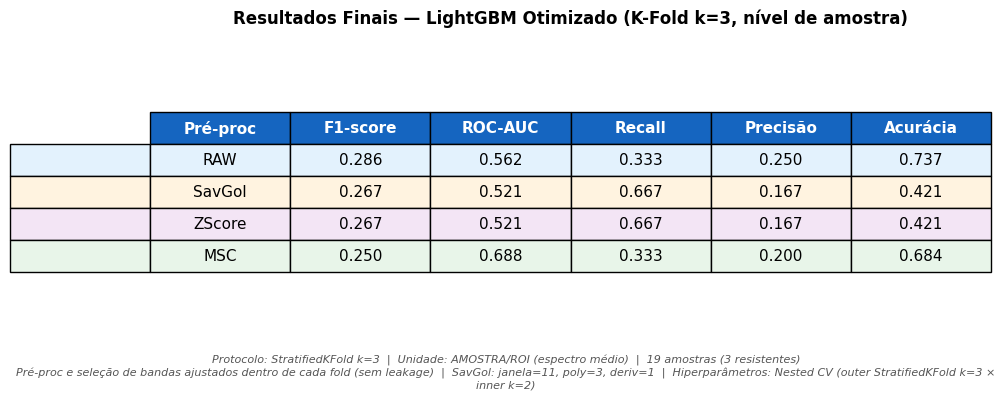

Figura salva: tabela_resultados_final.png


In [8]:
# Salva a tabela de resultados como PNG para a apresentação.
OUTPUT_DIR = ROOT_DIR / "data" / "gold level" / "features_extraidas"

fig, ax = plt.subplots(figsize=(10, 4))
ax.axis("off")

COLS_TABELA = ["Pré-proc", "F1-score", "ROC-AUC", "Recall", "Precisão", "Acurácia"]
cols_ok = [c for c in COLS_TABELA if c in df_res.columns]
df_tab = df_res[cols_ok].sort_values("F1-score", ascending=False).reset_index(drop=True)

cell_text = []
for _, row in df_tab.iterrows():
    cell_text.append([f"{v:.3f}" if isinstance(v, float) else str(v) for v in row])

cores_linha = {"MSC": "#E8F5E9", "RAW": "#E3F2FD", "SavGol": "#FFF3E0", "ZScore": "#F3E5F5"}
row_colors = [[cores_linha.get(row[0], "#FFFFFF")] * len(df_tab.columns) for row in cell_text]

tbl = ax.table(cellText=cell_text, colLabels=list(df_tab.columns),
               cellLoc="center", loc="center",
               rowColours=[r[0] for r in row_colors], cellColours=row_colors)
tbl.auto_set_font_size(False); tbl.set_fontsize(11); tbl.scale(1, 2.0)
for j in range(len(df_tab.columns)):
    tbl[(0, j)].set_facecolor("#1565C0")
    tbl[(0, j)].set_text_props(color="white", fontweight="bold")

legenda = (
    "Protocolo: StratifiedKFold k=3  |  Unidade: AMOSTRA/ROI (espectro médio)  |  "
    "19 amostras (3 resistentes)\n"
    "Pré-proc e seleção de bandas ajustados dentro de cada fold (sem leakage)  |  "
    "SavGol: janela=11, poly=3, deriv=1  |  "
    "Hiperparâmetros: Nested CV (outer StratifiedKFold k=3 × inner k=2)"
)
fig.text(0.5, 0.02, legenda, ha="center", fontsize=8, style="italic", color="#555555", wrap=True)

plt.title("Resultados Finais — LightGBM Otimizado (K-Fold k=3, nível de amostra)",
          fontsize=12, fontweight="bold", pad=15)
plt.tight_layout(rect=[0, 0.10, 1, 1])
plt.savefig(OUTPUT_DIR / "tabela_resultados_final.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figura salva: tabela_resultados_final.png")

## Matrizes de Confusão — todos os pré-processamentos

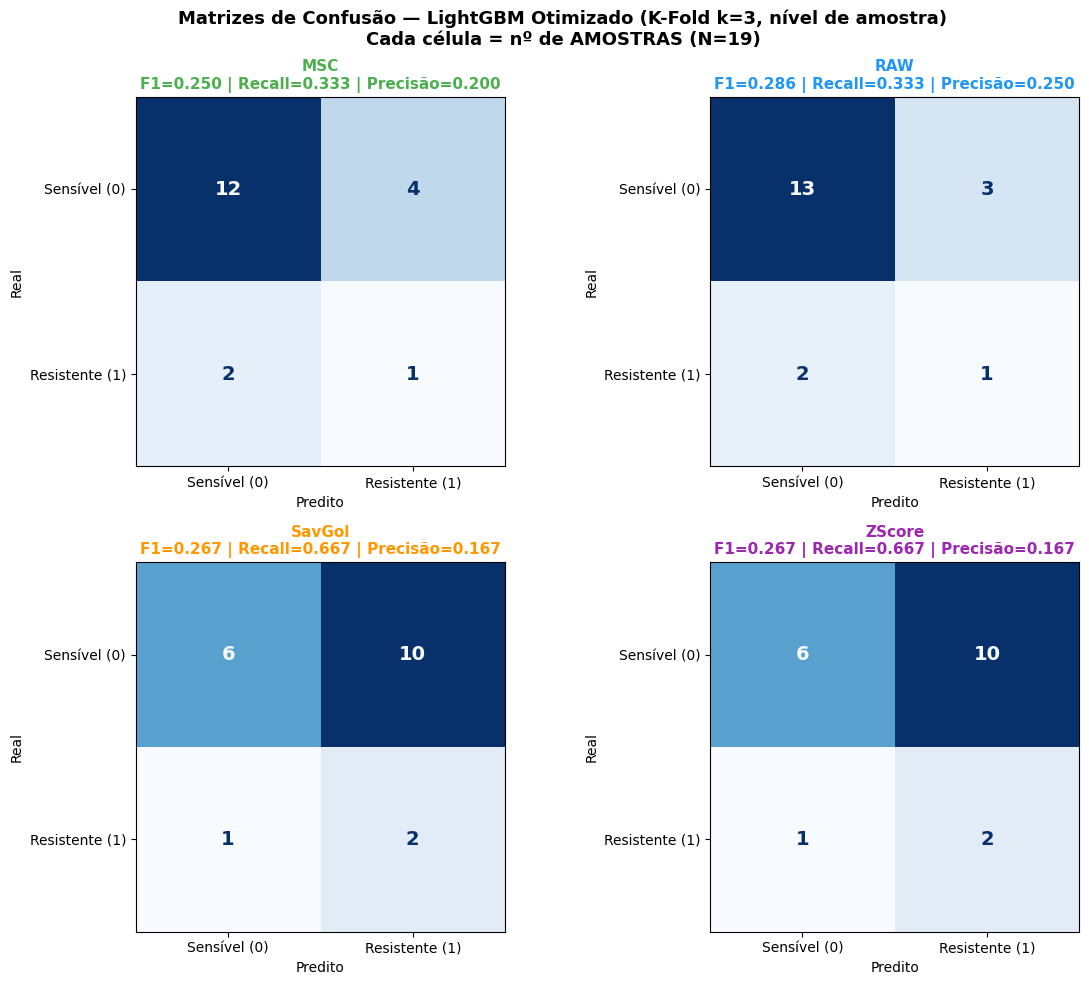

Figura salva: matrizes_confusao_nb08.png


In [9]:
# Matrizes de confusão no nível de AMOSTRA (19 predições held-out via K-Fold k=3).
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle("Matrizes de Confusão — LightGBM Otimizado (K-Fold k=3, nível de amostra)\n"
             "Cada célula = nº de AMOSTRAS (N=19)",
             fontsize=13, fontweight="bold")

cores_pre = {"MSC": "#4CAF50", "RAW": "#2196F3", "SavGol": "#FF9800", "ZScore": "#9C27B0"}

for ax, nome_pre in zip(axes.flat, ["MSC", "RAW", "SavGol", "ZScore"]):
    pred = predicoes_por_pre[nome_pre]
    y_true = pred["y_true"].values
    y_pred = pred["y_pred"].values

    f1   = f1_score(y_true, y_pred, zero_division=0)
    rec  = recall_score(y_true, y_pred, zero_division=0)
    prec = precision_score(y_true, y_pred, zero_division=0)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                  display_labels=["Sensível (0)", "Resistente (1)"])
    disp.plot(ax=ax, colorbar=False, cmap="Blues", values_format="d")
    for text in ax.texts:
        text.set_fontsize(14); text.set_fontweight("bold")
    ax.set_title(f"{nome_pre}\nF1={f1:.3f} | Recall={rec:.3f} | Precisão={prec:.3f}",
                 fontsize=11, fontweight="bold", color=cores_pre[nome_pre])
    ax.set_xlabel("Predito", fontsize=10); ax.set_ylabel("Real", fontsize=10)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "matrizes_confusao_nb08.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figura salva: matrizes_confusao_nb08.png")

## Comparação visual — antes vs depois da otimização

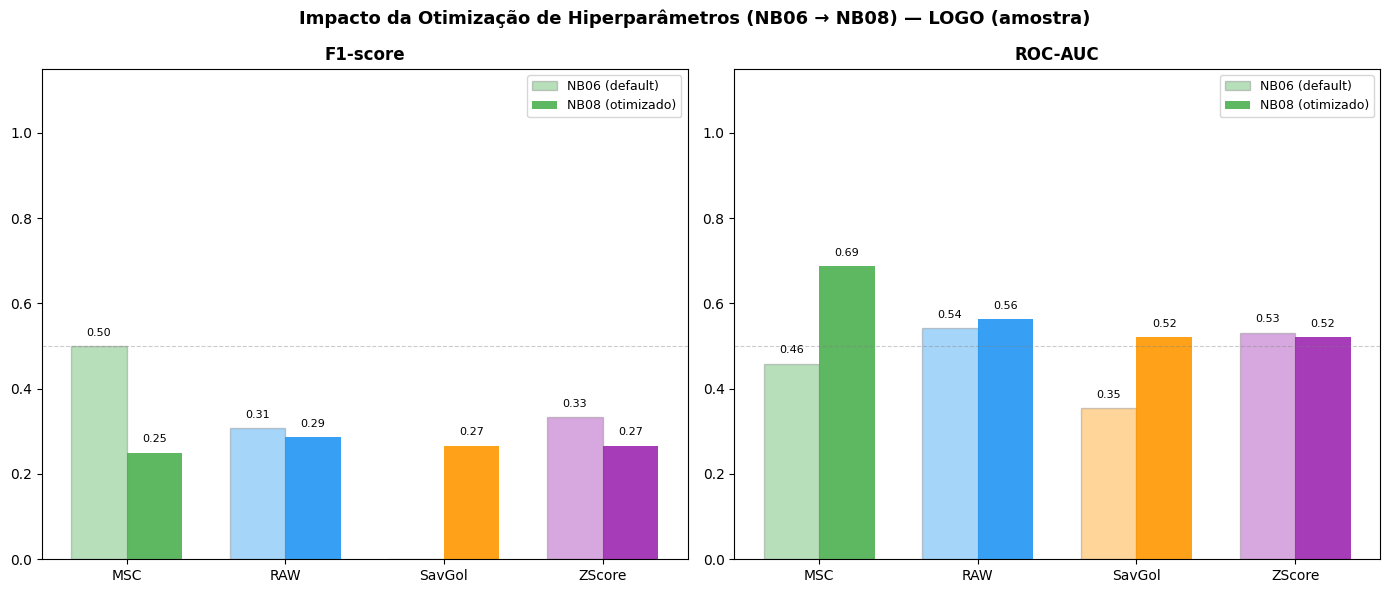

Figura salva: comparacao_otimizacao_nb06_nb08.png


In [10]:
# Comparação NB06 (params default) → NB08 (params otimizados), ambos nível de amostra.
# Lê o melhor F1/AUC por pré-processamento do NB06 (resultados_notebook06_roi.csv).
nb06_csv = OUTPUT_DIR / "resultados_notebook06_roi.csv"
NB06_F1, NB06_AUC = {}, {}
if nb06_csv.exists():
    df06 = pd.read_csv(nb06_csv)
    for p in ["MSC", "RAW", "SavGol", "ZScore"]:
        sub = df06[df06["Pré-proc"] == p]
        if len(sub):
            best = sub.loc[sub["F1-score"].idxmax()]
            NB06_F1[p], NB06_AUC[p] = best["F1-score"], best["ROC-AUC"]

pre_procs = ["MSC", "RAW", "SavGol", "ZScore"]
cores_pre = {"MSC": "#4CAF50", "RAW": "#2196F3", "SavGol": "#FF9800", "ZScore": "#9C27B0"}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Impacto da Otimização de Hiperparâmetros (NB06 → NB08) — LOGO (amostra)",
             fontsize=13, fontweight="bold")

x = np.arange(len(pre_procs)); width = 0.35

for ax, (col_res, nb06_vals, titulo) in zip(axes, [
    ("F1-score", NB06_F1,  "F1-score"),
    ("ROC-AUC",  NB06_AUC, "ROC-AUC"),
]):
    vals_antes  = [nb06_vals.get(p, 0) for p in pre_procs]
    vals_depois = [df_res.loc[df_res["Pré-proc"] == p, col_res].values[0]
                   if (df_res["Pré-proc"] == p).any() else 0 for p in pre_procs]

    bars1 = ax.bar(x - width/2, vals_antes,  width, label="NB06 (default)",
                   color=[cores_pre[p] for p in pre_procs], alpha=0.4, edgecolor="gray")
    bars2 = ax.bar(x + width/2, vals_depois, width, label="NB08 (otimizado)",
                   color=[cores_pre[p] for p in pre_procs], alpha=0.9)

    ax.set_title(titulo, fontweight="bold")
    ax.set_xticks(x); ax.set_xticklabels(pre_procs)
    ax.set_ylim(0, 1.15)
    ax.axhline(0.5, color="gray", linestyle="--", alpha=0.4, linewidth=0.8)
    ax.legend(fontsize=9)
    for bar in list(bars1) + list(bars2):
        h = bar.get_height()
        if h > 0.01:
            ax.text(bar.get_x() + bar.get_width()/2, h + 0.02, f"{h:.2f}",
                    ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "comparacao_otimizacao_nb06_nb08.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figura salva: comparacao_otimizacao_nb06_nb08.png")

## Feature Importance — melhor pré-processamento

Melhor pré-processamento: RAW (selecao=None, derivadas=True)


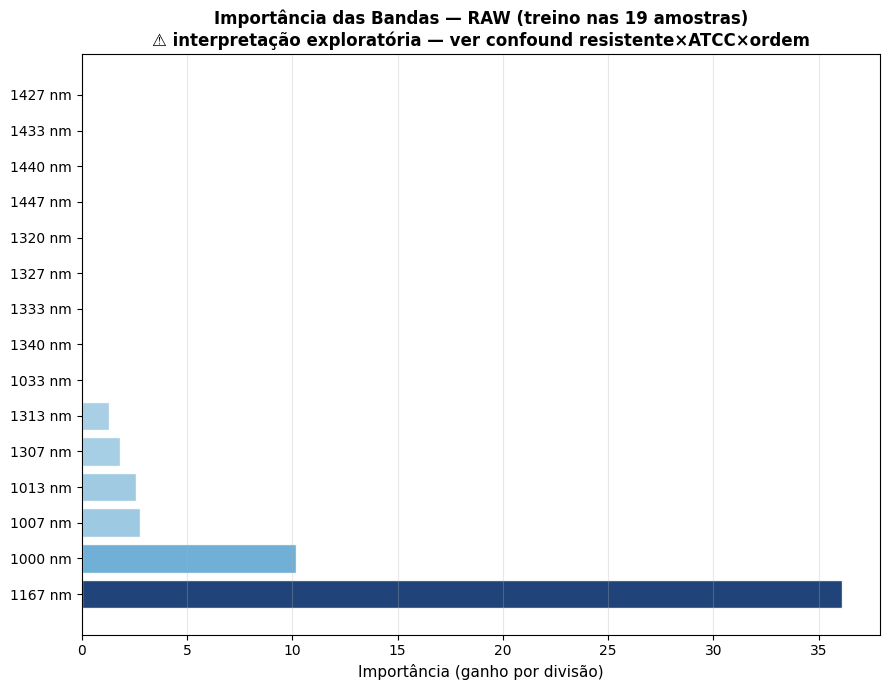

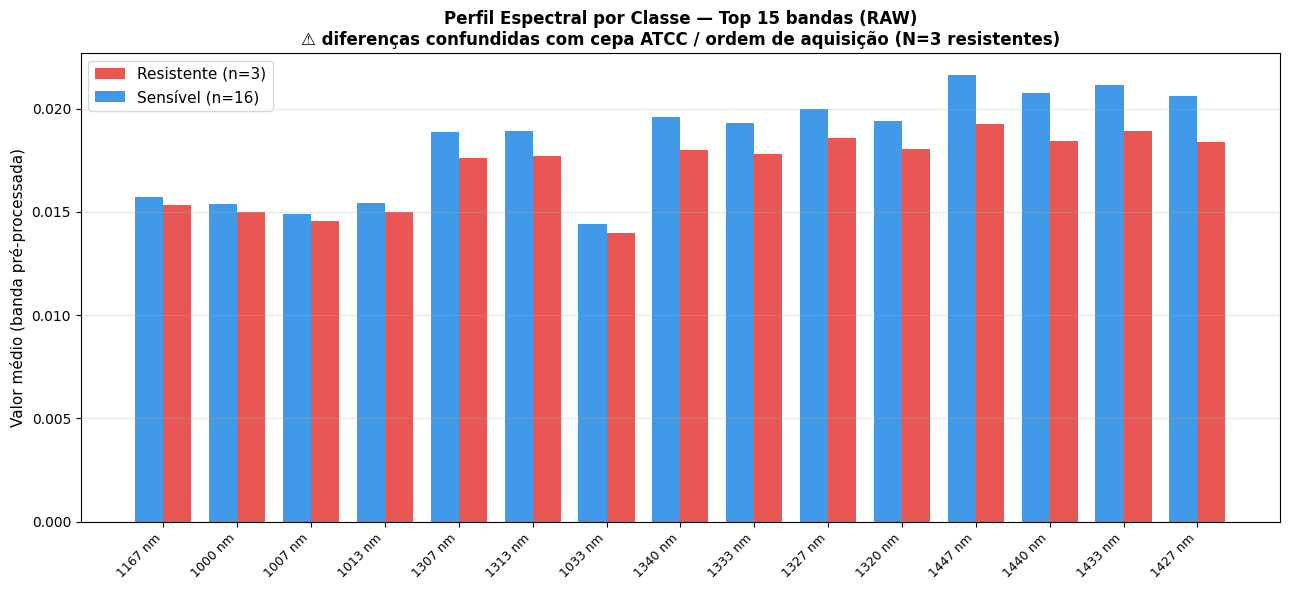


Top 10 features (RAW):


,label,importance
0,deriv_77,328.43
1,deriv_122,171.54
2,deriv_128,150.46
3,1167 nm,36.11
4,deriv_5,27.68
5,deriv_0,11.95
6,deriv_33,11.10
7,deriv_78,11.04
8,1000 nm,10.19
9,skewness,8.26


In [11]:
# ── Feature Importance + perfil espectral — melhor pré-processamento ──────────
# Treina nas 19 amostras (interpretação, NÃO avaliação). Pré-proc global aqui.
OUTPUT_DIR = ROOT_DIR / "data" / "gold level" / "features_extraidas"

melhor_pre = df_res.loc[df_res["F1-score"].idxmax(), "Pré-proc"]
cfg_best   = CONFIGS[melhor_pre]
metodo_sel = _MAP_SEL(cfg_best["metodo_selecao"])
k_bandas   = cfg_best["k_bandas"]
derivadas  = cfg_best["incluir_features_derivadas"]
print(f"Melhor pré-processamento: {melhor_pre} (selecao={metodo_sel}, derivadas={derivadas})")

# Pré-processa globalmente (interpretação) e seleciona bandas
pre = build_preprocessor(cfg_best.get("metodo_pre", _MAP_PRE[melhor_pre]))
df_pp = df_roi.copy()
df_pp[band_cols] = pre.fit_transform(df_roi[band_cols].values)
bandas_sel = (selecionar_bandas_consenso(df_pp, k=k_bandas, metodo=metodo_sel)
              if metodo_sel is not None else None)

gold = build_gold_matrix(df_pp, bandas_selecionadas=bandas_sel,
                         incluir_features_derivadas=derivadas)
META = ["sample_id", "target"]
X = gold.drop(columns=[c for c in META if c in gold.columns])
y = gold["target"].values
model = LGBMClassifier(**params_completos(cfg_best))
model.fit(X, y)

df_fi = pd.DataFrame({"feature": list(X.columns),
                      "importance": model.feature_importances_}
                     ).sort_values("importance", ascending=False).reset_index(drop=True)

# Bandas selecionadas → nm (band_i refere-se à i-ésima banda de bandas_sel)
bandas_ref = bandas_sel if bandas_sel is not None else band_cols
def label_feature(f):
    if f.startswith("band_"):
        idx = int(f.split("_")[1])
        if idx < len(bandas_ref):
            return f"{banda_para_nm(bandas_ref[idx]):.0f} nm"
    return f
df_fi["label"] = df_fi["feature"].apply(label_feature)

# ── Figura 1: importância das bandas (nm) ─────────────────────────────────────
df_bandas = df_fi[df_fi["feature"].str.startswith("band_")].head(k_bandas).reset_index(drop=True)
fig1, ax1 = plt.subplots(figsize=(9, 7))
norm_imp = df_bandas["importance"].values / (df_bandas["importance"].max() + 1e-9)
colors = plt.cm.Blues(0.35 + 0.65 * norm_imp)[::-1]
ax1.barh(range(len(df_bandas)), df_bandas["importance"].values[::-1], color=colors,
         alpha=0.9, edgecolor="white")
ax1.set_yticks(range(len(df_bandas)))
ax1.set_yticklabels(df_bandas["label"].values[::-1], fontsize=10)
ax1.set_xlabel("Importância (ganho por divisão)", fontsize=11)
ax1.set_title(f"Importância das Bandas — {melhor_pre} (treino nas 19 amostras)\n"
              f"⚠️ interpretação exploratória — ver confound resistente×ATCC×ordem",
              fontsize=12, fontweight="bold")
ax1.invert_yaxis(); ax1.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_importance_bandas_nm.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Figura 2: perfil espectral médio Resistente vs Sensível (top bandas) ─────
top_feats = df_bandas["feature"].tolist()
top_labels = df_bandas["label"].tolist()
med_res = gold.loc[gold["target"] == 1, top_feats].mean().values
med_sen = gold.loc[gold["target"] == 0, top_feats].mean().values

x_pos = range(len(top_feats)); width = 0.38
fig2, ax2 = plt.subplots(figsize=(13, 6))
ax2.bar([p + width/2 for p in x_pos], med_res, width, label="Resistente (n=3)", color="#E53935", alpha=0.85)
ax2.bar([p - width/2 for p in x_pos], med_sen, width, label="Sensível (n=16)",  color="#1E88E5", alpha=0.85)
ax2.set_xticks(list(x_pos)); ax2.set_xticklabels(top_labels, rotation=45, ha="right", fontsize=9)
ax2.set_ylabel("Valor médio (banda pré-processada)", fontsize=11)
ax2.set_title(f"Perfil Espectral por Classe — Top {len(top_feats)} bandas ({melhor_pre})\n"
              f"⚠️ diferenças confundidas com cepa ATCC / ordem de aquisição (N=3 resistentes)",
              fontsize=12, fontweight="bold")
ax2.legend(fontsize=11); ax2.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_importance_resistente_vs_sensivel.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nTop 10 features ({melhor_pre}):")
display(df_fi[["label", "importance"]].head(10).round(2))

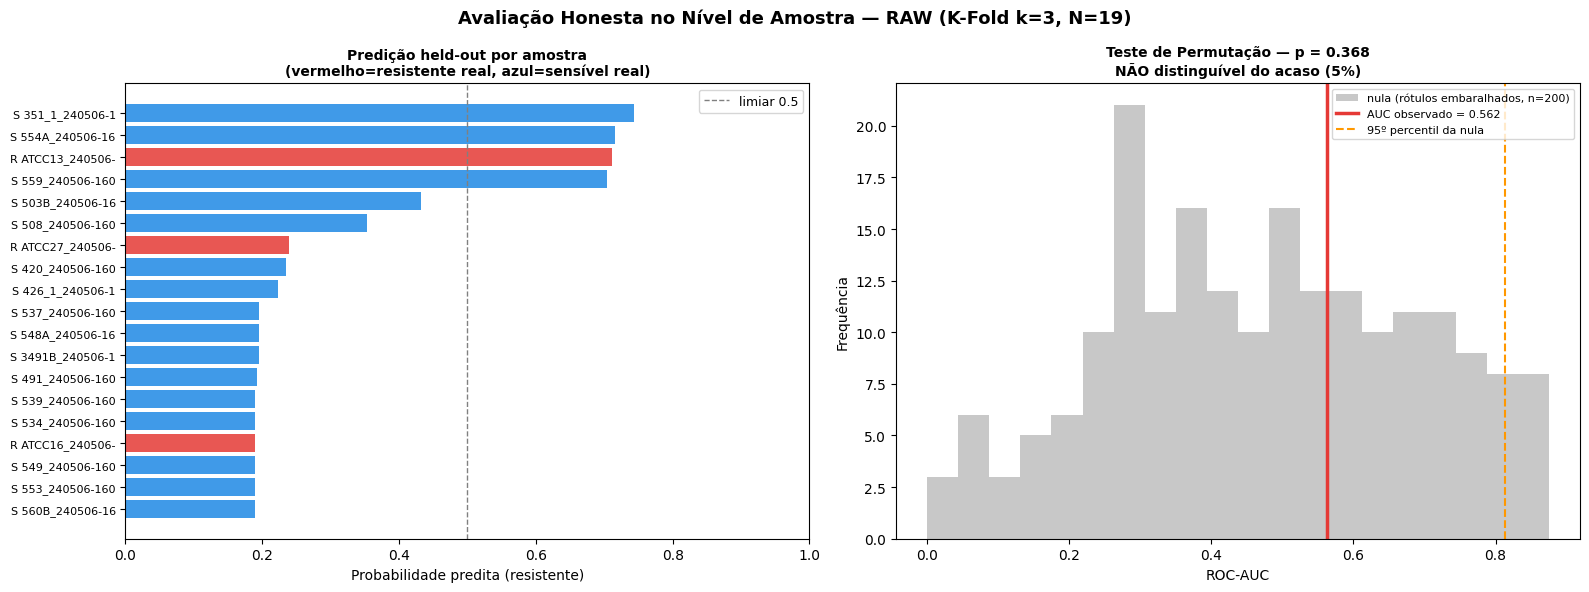

Figura salva: predicao_amostra_e_permutacao.png


In [12]:
# ── Predição por amostra + teste de permutação (visualização honesta final) ───
OUTPUT_DIR = ROOT_DIR / "data" / "gold level" / "features_extraidas"

pred = predicoes_por_pre[melhor_pre].copy()
pred["acerto"] = (pred["y_pred"] == pred["y_true"])
pred = pred.sort_values("y_prob").reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(f"Avaliação Honesta no Nível de Amostra — {melhor_pre} (K-Fold k=3, N=19)",
             fontsize=13, fontweight="bold")

# Esquerda: probabilidade predita por amostra (held-out)
ax = axes[0]
cores = ["#E53935" if t == 1 else "#1E88E5" for t in pred["y_true"]]
ax.barh(range(len(pred)), pred["y_prob"], color=cores, alpha=0.85)
ax.axvline(0.5, color="gray", linestyle="--", linewidth=1, label="limiar 0.5")
ax.set_yticks(range(len(pred)))
ax.set_yticklabels([f"{'R' if t==1 else 'S'} {sid[:14]}"
                    for sid, t in zip(pred["sample_id"], pred["y_true"])], fontsize=8)
ax.set_xlabel("Probabilidade predita (resistente)", fontsize=10)
ax.set_xlim(0, 1)
ax.set_title("Predição held-out por amostra\n(vermelho=resistente real, azul=sensível real)",
             fontsize=10, fontweight="bold")
ax.legend(fontsize=9)

# Direita: distribuição nula da permutação vs AUC observado
ax = axes[1]
if "perm" in dir():
    ax.hist(perm["nulos"], bins=20, color="#BBBBBB", alpha=0.8,
            label=f"nula (rótulos embaralhados, n={perm['n_perm']})")
    ax.axvline(perm["observado"], color="#E53935", linewidth=2.5,
               label=f"AUC observado = {perm['observado']:.3f}")
    ax.axvline(np.nanpercentile(perm["nulos"], 95), color="#FF9800",
               linestyle="--", linewidth=1.5, label="95º percentil da nula")
    ax.set_title(f"Teste de Permutação — p = {perm['p_valor']:.3f}\n"
                 f"{'NÃO ' if perm['p_valor'] > 0.05 else ''}distinguível do acaso (5%)",
                 fontsize=10, fontweight="bold")
    ax.set_xlabel("ROC-AUC", fontsize=10); ax.set_ylabel("Frequência", fontsize=10)
    ax.legend(fontsize=8)
else:
    ax.text(0.5, 0.5, "Rode a célula de avaliação (permutação) primeiro.",
            ha="center", va="center")
    ax.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "predicao_amostra_e_permutacao.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figura salva: predicao_amostra_e_permutacao.png")

## Predição por Amostra e Teste de Permutação

## Salvar resultados finais

In [13]:
OUTPUT_DIR = ROOT_DIR / "data" / "gold level" / "features_extraidas"

resumo_final = {
    "protocolo": "StratifiedKFold k=3 — nível de amostra",
    "n_amostras": int(df_roi.shape[0]),
    "n_resistentes": int(df_roi["target"].sum()),
    "configuracoes": {
        pre: {
            "metodo_pre":                 cfg.get("metodo_pre", _MAP_PRE[pre]),
            "metodo_selecao":             cfg["metodo_selecao"],
            "k_bandas":                   cfg["k_bandas"],
            "incluir_features_derivadas": cfg["incluir_features_derivadas"],
            "hiperparametros":            cfg["melhores_params"],
        }
        for pre, cfg in CONFIGS.items()
    },
    "resultados_cv": {
        row["Pré-proc"]: {
            "F1":     round(float(row["F1-score"]), 4),
            "AUC":    round(float(row["ROC-AUC"]), 4),
            "Recall": round(float(row["Recall"]), 4),
        }
        for _, row in df_res.iterrows()
    },
    "permutacao_melhor": (
        {"pre_proc": melhor_pre,
         "auc_observado": round(float(perm["observado"]), 4),
         "p_valor": round(float(perm["p_valor"]), 4),
         "n_perm": perm["n_perm"]}
        if "perm" in dir() else None
    ),
}

with open(OUTPUT_DIR / "resumo_modelo_final.json", "w", encoding="utf-8") as f:
    json.dump(resumo_final, f, indent=2, ensure_ascii=False)

print("Resumo salvo: resumo_modelo_final.json")
print(json.dumps(resumo_final, indent=2, ensure_ascii=False))

Resumo salvo: resumo_modelo_final.json
{
  "protocolo": "StratifiedKFold k=3 — nível de amostra",
  "n_amostras": 19,
  "n_resistentes": 3,
  "configuracoes": {
    "MSC": {
      "metodo_pre": "msc",
      "metodo_selecao": "mi",
      "k_bandas": 15,
      "incluir_features_derivadas": false,
      "hiperparametros": {
        "boosting_type": "gbdt",
        "feature_fraction": 0.7,
        "lambda_l1": 0.0,
        "lambda_l2": 0.1,
        "learning_rate": 0.01,
        "max_depth": 3,
        "min_child_samples": 2,
        "num_leaves": 7
      }
    },
    "RAW": {
      "metodo_pre": "raw",
      "metodo_selecao": "None",
      "k_bandas": 15,
      "incluir_features_derivadas": true,
      "hiperparametros": {
        "boosting_type": "gbdt",
        "feature_fraction": 0.7,
        "lambda_l1": 0.0,
        "lambda_l2": 0.1,
        "learning_rate": 0.01,
        "max_depth": 3,
        "min_child_samples": 2,
        "num_leaves": 7
      }
    },
    "SavGol": {
      "met